# Training sequence to accessibility models

In the previous section, we have preprocessed ATAC data and curated a set of regions suitable for model training.<br>
In this section, we use these regions to train DeepSTARR type sequence-to-accessibility models.<br>
As a first step, we define the genomic regions and ATAC signal files that we plan on using for training and evaluation

In [1]:
import os
import sys
from pathlib import Path

def find_repo_root(marker="environment.yml"):
    """Walk up from the current working directory until a folder containing `marker` is found."""
    start = Path().resolve()
    for parent in [start, *start.parents]:
        if (parent / marker).exists():
            return parent
    raise RuntimeError(
        f"Could not find repo root: no '{marker}' found in {start} or any parent directory."
    )

repo_base_dir = str(find_repo_root())
os.environ["REPO_BASE_DIR"] = repo_base_dir  # so %%bash cells below can use $REPO_BASE_DIR

import pandas as pd

In [2]:
#Loading peak regions
peak_regions_file = f"{repo_base_dir}/res/ENCODE_cellines/GM12878/curated_regions/peak_regions_filtered.tsv"
peak_regions = pd.read_csv(peak_regions_file,sep="\t")


#Loading (GC matched) control regions
control_regions_file = f"{repo_base_dir}/res/ENCODE_cellines/GM12878/curated_regions/gc_matched_control_regions_filtered.tsv"
control_regions = pd.read_csv(control_regions_file, sep = "\t")

#Fasta file containing the reference genome --> for fetching the sequences of the regions
genome_fasta = f'{repo_base_dir}/example_data/reference_genomes/hg38/hg38.fa'

#Bigwig file containing the signal that we want to predict: ATAC signal in the cell type of interest --> for fetching the ATAC signals of the regions
atac_signal_bigwig = f"{repo_base_dir}/res/ENCODE_cellines/GM12878/ATAC_signal_files/ENCFF415FEC_insertions.bw"

In [3]:
peak_regions

,chrom,start,end
0,chr1,10250,10651
1,chr1,778415,779160
2,chr1,804460,805570
3,chr1,826912,828018
4,chr1,865605,865994
...,...,...,...
63198,chr9,137808496,137809381
63199,chr9,137816258,137817168
63200,chr9,137825344,137826249
63201,chr9,137866262,137867042


The regions are loaded into BED style pandas data frames, the first three columns indicate chromosome, start and end of a region.

### Train test splitting
In machine learning, it is always important to seperate data points used for training from datapoints used for evaluation.<br>
The reason is that we need to have a reliable way of measuring how well our model performs, however there is always the possibility that a model just "memorises" training data without learning generalisable rules,<br>
which is why we need a held out set of examples that is not used for training which we can use for testing to which degree the model has learned generalisable rules.<br>
In genomics, we most often perform this train/validation/test splitting along chromosome, so regions from certain chromosomes are used for training while regions from other chromosomes are reserved for validation and testing.<br>
Both validation set as well as test sequences are used for evaluating model performance, but while test set sequence are reserved for obtaining a final, reliable performance estimate once training is finished,<br> validation set sequences are used for continuously evaluating the model throughout the training process to decide when training is finished (i.e. the model performance does not improve anymore)


In [4]:
all_autosomes = [f"chr{i}" for i in range(1,23)]

test_chroms = ["chr1","chr22"]
val_chroms = ["chr2","chr21"]
train_chroms = [chrom for chrom in all_autosomes if chrom not in test_chroms+val_chroms]

In [5]:
print("Chromosomes for training",train_chroms)

Chromosomes for training ['chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20']


In [6]:
print("Chromosomes for validation",val_chroms)

Chromosomes for validation ['chr2', 'chr21']


In [7]:
print("Chromosomes for final testing",test_chroms)

Chromosomes for final testing ['chr1', 'chr22']


For the training data, we construct a data loader/generator as described in the previous notebook.<br>
For the test and validation regions, we can afford to load the whole data into memory. For this we use the function extract_loci from the tangermeme package.<br>
As before, we apply a log1p transformation of total insertion counts.

### Dataloaders

During training, we need to sequentially present batches of examples to the model.<br>
Dataloaders facilitate this job as they automate the fetching of sequences and ATAC signals for certain regions.<br> 
In the following, we are going to build a pytorch dataset that uses tangermeme's extract_loci function to load genomic sequences and ATAC signals and then use a pytorch dataloader to yield batches of examples.

In [10]:
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from tangermeme.io import extract_loci
import torch


class Sequence2FunctionDataset(Dataset):
    
    def __init__(
        self, 
        regions,
        genome_fasta,
        signal_bw_files,
        chroms=None,
        log1p_insertion_counts=True
        ):
        """
        Args:
            regions (list): list of pandas.DataFrames with chrom,start,end columns
            genome_fasta (str): path to reference genome fasta file
            signal_bw_files (list): list of filepaths to signal bigwig files
            chroms (list of str or None): list of chromosome names to consider when loading.
        """
        
        
        self.regions = regions
        self.genome_fasta=genome_fasta
        self.signal_bw_files = signal_bw_files
        self.chroms=chroms
        
        #Load sequences and signals
        
        self.seqs, self.signals = extract_loci(
            self.regions,
            self.genome_fasta,
            signals=self.signal_bw_files,
            chroms=self.chroms,
            in_signals=None,
            in_window=1001,
            out_window=1001,
            ignore=list('QWERYUIOPSDFHJKLZXVBNM'), 
            verbose=True
        )
        
        if log1p_insertion_counts:
            self.signals = torch.log2(1+self.signals.sum(axis=-1))
            
    def __len__(self):
        return self.seqs.shape[0]

    def __getitem__(self, idx):
        seq,sign = self.seqs[idx], self.signals[idx]
        return seq, sign

We can iterate over the data loader object and it will yield us batches of example regions, that is batches of sequences and batches of ATAC profiles

In [11]:
all_regions = pd.concat([peak_regions,control_regions])

##########################
#Loading data for training
##########################

train_dataset = Sequence2FunctionDataset(
    [all_regions], #Peak+background regions
    genome_fasta, #Reference genome for extracting loci's DNA sequences
    [atac_signal_bigwig], #ATAC signal bigwig for extracting loci's ATAC signals
    chroms=train_chroms #Defines regions from which chromosomes to return
)

train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)

Loading Loci: 100%|██████████| 98923/98923 [00:15<00:00, 6356.11it/s]


In [12]:
for seqs_batch,atac_batch in train_dataloader:
    break #stop after first iteration, so we can have a look at the objects that the generator yields

In [13]:
#Batch of one hot encoded sequences: Shape (batch_size,n_nucleotides,region_length)
print(f"Shape of sequence batch: {seqs_batch.shape} (batch_size,n_nucleotides,region_length)")

Shape of sequence batch: torch.Size([64, 4, 1001]) (batch_size,n_nucleotides,region_length)


In [14]:
#Batch of ATAC profiles: Shape(batch_size,1,region_length)
print(f"Shape of ATAC signals batch: {atac_batch.shape} (batch_size,1)")

Shape of ATAC signals batch: torch.Size([64, 1]) (batch_size,1)


In [15]:
##################################################
#Loading data for validation and testing
############################################


#Validation data

val_seqs, val_signals= extract_loci(
    [peak_regions, control_regions],
    genome_fasta,
    signals=[atac_signal_bigwig], 
    chroms=val_chroms,
    in_signals=None,
    in_window=1001,
    out_window=1001,
    ignore=list('QWERYUIOPSDFHJKLZXVBNM'), 
    verbose=True
    )

val_signals_counts = val_signals.sum(dim=-1) #Calculate overall insertion number for every region
val_signals_counts = torch.log2(1+val_signals_counts) #Apply log1p transform

#Test data

test_seqs, test_signals= extract_loci(
    [peak_regions, control_regions],
    genome_fasta,
    signals=[atac_signal_bigwig], 
    chroms=test_chroms,
    in_signals=None,
    in_window=1001,
    out_window=1001,
    ignore=list('QWERYUIOPSDFHJKLZXVBNM'), 
    verbose=True
    )

test_signals_counts = test_signals.sum(dim=-1) #Calculate overall insertion number for every region
test_signals_counts = torch.log2(1+test_signals_counts) #Apply log1p transform

#####################################

Loading Loci: 100%|██████████| 14791/14791 [00:04<00:00, 3413.54it/s]


In [16]:
print("11692 one hot encoded sequences for validation: ", val_seqs.shape)
print("11692 ATAC count signals for validation: ", val_signals_counts.shape,"\n")

print("14791 one hot encoded sequences for testing: ", test_seqs.shape)
print("14791 ATAC count signals for testing: ", test_signals_counts.shape)

11692 one hot encoded sequences for validation:  torch.Size([11692, 4, 1001])
11692 ATAC count signals for validation:  torch.Size([11692, 1]) 

14791 one hot encoded sequences for testing:  torch.Size([14791, 4, 1001])
14791 ATAC count signals for testing:  torch.Size([14791, 1])


### Model training
For training a deep learning model, we need the model itself and we need to have a way of updating the models parameters according to new training data in a way that improves the models performance.<br>
In practive, this means having:
- A model object (architecture and parameter weights)
- A loss function (measuring "how far off" models predictions are, given a certain ground truth)
- An optimizer (updates model parameter weights given information from the loss function)

For training our sequence to accessibility model, we use the DeepSTARR architecture (a small convolutional neural network) together with the mean squared error (MSE) loss fuction (for regression tasks) as well as the Adam optimiser.

In [17]:
#Importing model architecture
sys.path.append(f"{repo_base_dir}/src/01_model_architectures/")
from model_architectures import deepstarr_default_params, DeepSTARR

In [18]:
#Creating a model object and moving it to the device used for training (that is the GPU if one is available)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = DeepSTARR(**deepstarr_default_params).to(device)
model 

DeepSTARR(
  (conv1): Conv1d(4, 256, kernel_size=(7,), stride=(1,), padding=same)
  (conv1_bn): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu1): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (layers_cnn): ModuleList(
    (0): Conv1d(256, 120, kernel_size=(3,), stride=(1,), padding=same)
    (1): BatchNorm1d(120, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(120, 60, kernel_size=(3,), stride=(1,), padding=same)
    (5): BatchNorm1d(60, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(60, 60, kernel_size=(3,), stride=(1,), padding=same)
    (9): BatchNorm1d(60, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU

In [20]:
#Creating loss function and optimizer objects
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

In [21]:
from tangermeme.predict import predict
from scipy.stats import pearsonr

The following code constitutes the actual training loop.<br>
We iterate over all the examples in the training set in batches and update model weights as we go.<br>
One pass over all training examples is called an epoch and we train for several epochs.<br>
After an epoch is finished, we evaluate the predictive performance of the model by measuring how well predicted and observed accessibility correlate across all validation set examples.<br>
To see if we have trained for long enough, we can plot the development of the validation performance across the epochs, if with a given number of epochs no plateau is reached we might consider training for longer,<br>
if we see that validation performance is dropping again (-> overfitting), we should reduce the number of epochs.

In [22]:
%%time

##############
#Training loop
##############

max_epochs=20
pcc_over_epochs = []

#Directory and filepath for saving the model

model_savedir = f"{repo_base_dir}/res/ENCODE_cellines/GM12878/saved_models/"
os.makedirs(model_savedir, exist_ok=True)
model_filepath = f"{model_savedir}/model.pth"

print("Start training")
best_performance=-1

for epoch in range(max_epochs):
    #Set model in train mode
    model.train()
    
    ###########################################
    #Iterate over batches of the train data set
    ###########################################
    
    for i, (X_batch, y_batch) in enumerate(train_dataloader):
        
        ###################
        #Process batch data
        ###################
        
        #Batch => set of examples to process in one go
        X_batch = X_batch.to(device) #Data must be moved to the same device as the model via the .to method
        y_batch = y_batch.to(device)

        ##############
        #Training step
        ##############
        
        optimizer.zero_grad() #Reset gradients of the model parameters
        y_pred = model(X_batch) #make prediction for the current batche's sequences

        loss = loss_fn(y_pred, y_batch) #Evaluate loss for current batch, i.e how far off the predictions are from the ground truth
        loss.backward() #Take the derivative of the loss function with respect to the model parameters (the derivative informs about in which direction the parameters to change to make predictions "less wrong")
        optimizer.step() #Update the model weights according to the derivative of the loss function
        
    #################################################
    #Evaluate model performance on the validation set
    #################################################
    
    #Set model in evaluation mode
    model.eval()

    #Predicted vs observed accessibility 
    valid_signal_pred = predict(model, val_seqs, dtype=torch.float32, device=device) #Making predictions for all validation set sequences using tangermeme's predict function 
    r_valid = pearsonr(val_signals_counts, valid_signal_pred)[0][0] #Evaluating predictive performance by correlating predicted with observed accessibility across all validation set sequences
    pcc_over_epochs.append(r_valid)
    
    print(f"Epoch {epoch+1}/{max_epochs}\n ") 
    print(f"Validation Pearson R : {r_valid:.4f}\n") 

    #Check if a new best performance has been achieved
    #If so, save the model
    performance = r_valid
    if  performance > best_performance:
        best_performance = performance
        torch.save(model.state_dict(), model_filepath)
        print(f"NEW BEST MODEL saved with Validation Pearson R: {r_valid:.4f} at epoch {epoch+1}\n")
    
print("Training finished")

Start training
Epoch 1/20
 
Validation Pearson R : 0.5250

NEW BEST MODEL saved with Validation Pearson R: 0.5250 at epoch 1

Epoch 2/20
 
Validation Pearson R : 0.5994

NEW BEST MODEL saved with Validation Pearson R: 0.5994 at epoch 2

Epoch 3/20
 
Validation Pearson R : 0.6666

NEW BEST MODEL saved with Validation Pearson R: 0.6666 at epoch 3

Epoch 4/20
 
Validation Pearson R : 0.6683

NEW BEST MODEL saved with Validation Pearson R: 0.6683 at epoch 4

Epoch 5/20
 
Validation Pearson R : 0.6699

NEW BEST MODEL saved with Validation Pearson R: 0.6699 at epoch 5

Epoch 6/20
 
Validation Pearson R : 0.6732

NEW BEST MODEL saved with Validation Pearson R: 0.6732 at epoch 6

Epoch 7/20
 
Validation Pearson R : 0.6922

NEW BEST MODEL saved with Validation Pearson R: 0.6922 at epoch 7

Epoch 8/20
 
Validation Pearson R : 0.6972

NEW BEST MODEL saved with Validation Pearson R: 0.6972 at epoch 8

Epoch 9/20
 
Validation Pearson R : 0.6743

Epoch 10/20
 
Validation Pearson R : 0.6780

Epoch 11

Text(0.5, 1.0, 'Validation performance across epochs')

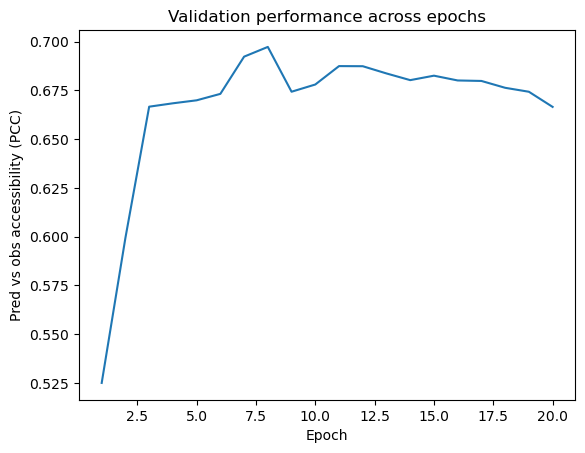

In [23]:
from matplotlib import pyplot as plt
import numpy as np

pcc_over_epochs = np.array(pcc_over_epochs)
epochs = np.arange(1,len(pcc_over_epochs)+1)

fig, ax = plt.subplots()
ax.plot(epochs,pcc_over_epochs)
ax.set_xlabel("Epoch")
ax.set_ylabel("Pred vs obs accessibility (PCC)")
ax.set_title("Validation performance across epochs")

### Model testing

After the model is trained, we can assess its performance on the held out test set of examples.<br>
For this, we reload the best version of the model, predict accessibility for all test set regions and evaluate how well predicted and observed accessibility correlate.<br>
In addition, we visualise dependence between predicted and true accessibility as a scatterplot where each point represents test set example.

In [24]:
#Region extraction for final testing

test_seqs, test_signals= extract_loci(
    [peak_regions, control_regions],
    genome_fasta,
    signals=[atac_signal_bigwig], 
    chroms=test_chroms,
    in_signals=None,
    in_window=1001,
    out_window=1001,
    ignore=list('QWERYUIOPSDFHJKLZXVBNM'), 
    verbose=True
    )

test_signals_counts = test_signals.sum(dim=-1) #Calculate overall insertion number for every region
test_signals_counts = torch.log2(1+test_signals_counts) #Apply log1p transform

#Remove sequences that contain Ns (all 0 columns in the one hot encoding)
non_n_selector = test_seqs.sum(axis=(-2,-1))==1001
test_seqs = test_seqs[non_n_selector]
test_signals_counts = test_signals_counts[non_n_selector]

Loading Loci: 100%|██████████| 14791/14791 [00:04<00:00, 3115.29it/s]


In [25]:
#Load best model

model.load_state_dict(
    torch.load(model_filepath)
)
model.eval()

/tmp/ipykernel_13308/621431642.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(model_filepath)


DeepSTARR(
  (conv1): Conv1d(4, 256, kernel_size=(7,), stride=(1,), padding=same)
  (conv1_bn): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu1): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (layers_cnn): ModuleList(
    (0): Conv1d(256, 120, kernel_size=(3,), stride=(1,), padding=same)
    (1): BatchNorm1d(120, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(120, 60, kernel_size=(3,), stride=(1,), padding=same)
    (5): BatchNorm1d(60, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(60, 60, kernel_size=(3,), stride=(1,), padding=same)
    (9): BatchNorm1d(60, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU

In [26]:
#Make predictions for all test set regions

test_signals_pred = predict(model, test_seqs, dtype=torch.float32, device=device) #Making predictions for all test set sequences using tangermeme's predict function 
r_test = pearsonr(test_signals_counts, test_signals_pred)[0][0] #Evaluating predictive performance by correlating predicted with observed accessibility across all test set sequences
print(f"PCC observed vs predicted accessibility: {r_test:.3f}")

PCC observed vs predicted accessibility: 0.709


Text(0.5, 1.0, 'Test set performance\nPCC=0.709')

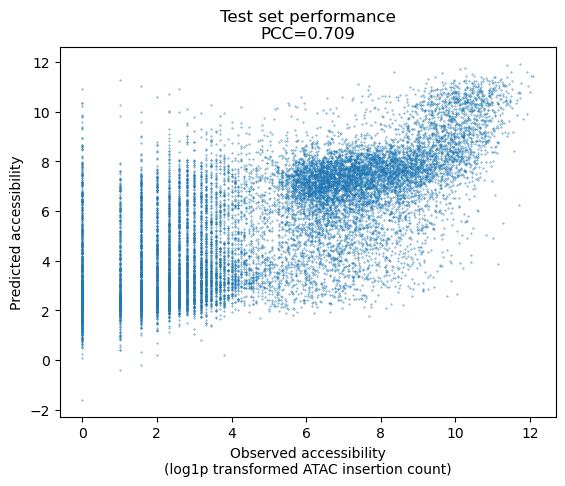

In [27]:
#Visualising predictions as scatterplot

fig, ax = plt.subplots()
ax.scatter(test_signals_counts, test_signals_pred,s=0.1)
ax.set_xlabel("Observed accessibility\n(log1p transformed ATAC insertion count)")
ax.set_ylabel("Predicted accessibility")
ax.set_title(f"Test set performance\nPCC={r_test:.3f}")

The performance on the test set is on par with the validation performances that we observed during training, that means that our model succeeds in generalising to held out examples.<br>
It seems that our model has successfully learned accessibility coding rules in the lymphoblastoid cellular context, however it is prudent to perform additional sanity checks:<br>
Deep learning models are powerful and flexible pattern recognition systems but due to this flexibility they can also easily home in on biases in the data that one might not be aware of.<br>
In genomics data, one needs to have a close look at GC content bias: Regulatory DNA regions are in general richer in G/C nucleotides (especially CG dinucleotides) than genomic background regions<br> without regulatory potential.<br>
This means, model can easily distingtest_seqsuish ATAC peak from background regions by just learning to count Cs and Gs.

One way to probe wheter our models have learned grammar rules that go beyond C/G counting, is run predictions on shuffled versions of test set sequences, keeping (di)nucleotide content the same but disrupting motifs.
If the predictions on the shuffled sequences still correlate with the true accessibility of the region, this means that predictions are guided by simple sequence composition features rather than complex grammar rules.

In [28]:
from tangermeme.ersatz import dinucleotide_shuffle



#Dinucleotide shuffle test sequences
X_test_dinuc_shuffled = dinucleotide_shuffle(test_seqs, n=1)[:,0,:,:]

#Check that nucleotide content in each sequence is still the same
X_nucsums = test_seqs.sum(axis=-1)
shuf_nucsums = X_test_dinuc_shuffled.sum(axis=-1)
(X_nucsums == shuf_nucsums).all()

tensor(True)

In [29]:
#Make predictions for shuffled sequences

y_test_shuffled_pred = predict(model, X_test_dinuc_shuffled, dtype=torch.float32, device=device) 
r_test_shuffled = pearsonr(test_signals_counts, y_test_shuffled_pred)[0][0] 
print(f"PCC observed vs predicted accessibility (shuffled sequences): {r_test_shuffled:.3f}")

PCC observed vs predicted accessibility (shuffled sequences): 0.323


Text(0.5, 1.0, 'Test set performance (Shuffled sequences)\nPCC=0.323')

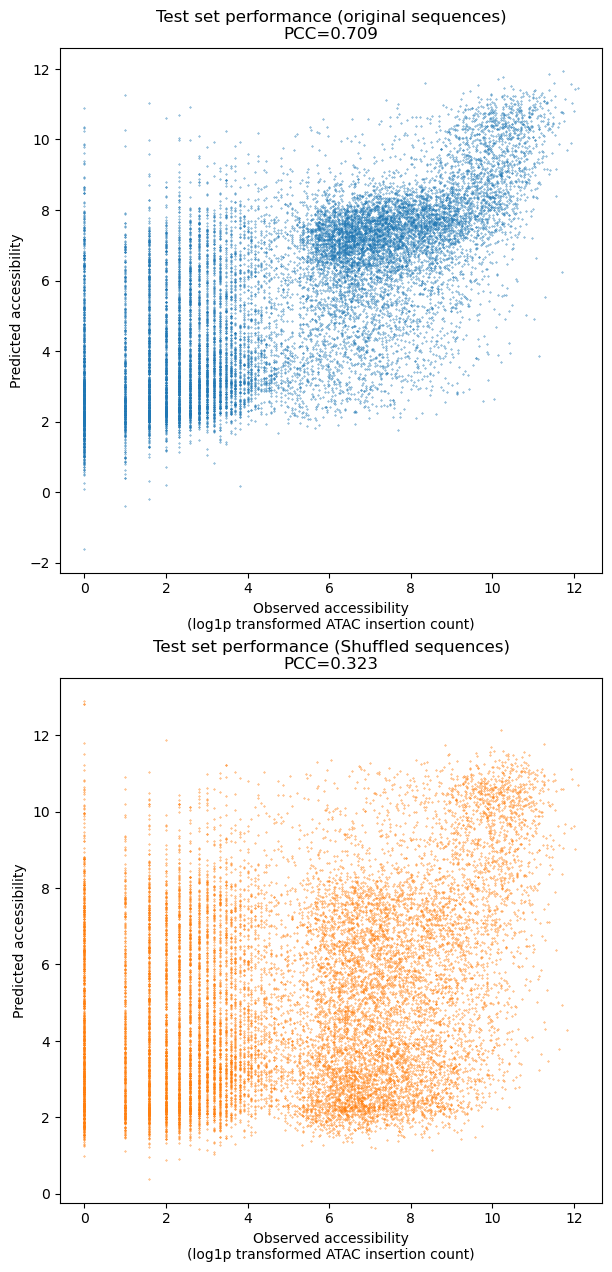

In [30]:
fig, ax = plt.subplots(nrows=2, figsize = (7,15))

ax[0].scatter(test_signals_counts, test_signals_pred,s=0.1, c="tab:blue")
ax[0].set_xlabel("Observed accessibility\n(log1p transformed ATAC insertion count)")
ax[0].set_ylabel("Predicted accessibility")
ax[0].set_title(f"Test set performance (original sequences)\nPCC={r_test:.3f}")

ax[1].scatter(test_signals_counts, y_test_shuffled_pred,s=0.1, c = "tab:orange")
ax[1].set_xlabel("Observed accessibility\n(log1p transformed ATAC insertion count)")
ax[1].set_ylabel("Predicted accessibility")
ax[1].set_title(f"Test set performance (Shuffled sequences)\nPCC={r_test_shuffled:.3f}")

For the shuffled sequences, the predicted vs observed correlation is markedly reduced.<br>
That means that our model is not only led by simple sequence composition features but has presumably learned more complex rules encoding DNA accessibility.<br>
To retrieve and interpret these sequence features and rules, we will have a look at interpretability methods in the next notebook.